# AI 최적화 & 엔지니어링 정리

---

### 1. 전이학습

#### 1-1. 개념

- 배경: 데이터 부족 → 과적합, 처음부터 학습하는 비용 큼
- **전이학습**
: 사전 학습으로 배운 능력을 새 작업 학습에 활용하는 것

- **핵심 용어 4가지**
    - Source: 기존에 학습한 문제
    - Target: 새로 풀 문제
    - Domain: 데이터의 특성
    - Task: 수행할 작업
    - Source와 Target의 **Domain이나 Task 중 하나라도 다를 때** 쓰는 것이 전이학습

#### 1-2. 분류

- **Domain과 Task 기준**
    - 귀납적: Task 다름, Target 레이블 필요 (예: 이미지 분류 → 객체 탐지)
    - 변환적: Domain 다름, Task 같음, Target 레이블 없음 (예: 뉴스 감정 분석 → 영화 리뷰 감정 분석)
    - 비지도: Source, Target 모두 레이블 없음 (예: 군집화 지식 → 다른 분야 군집화)

- **전이 대상 기준** 
    - 인스턴스 (데이터 일부) 
    - 특성 (특징 표현) 
    - 파라미터 (가중치, 편향) 
    - 관계 (관계 패턴)

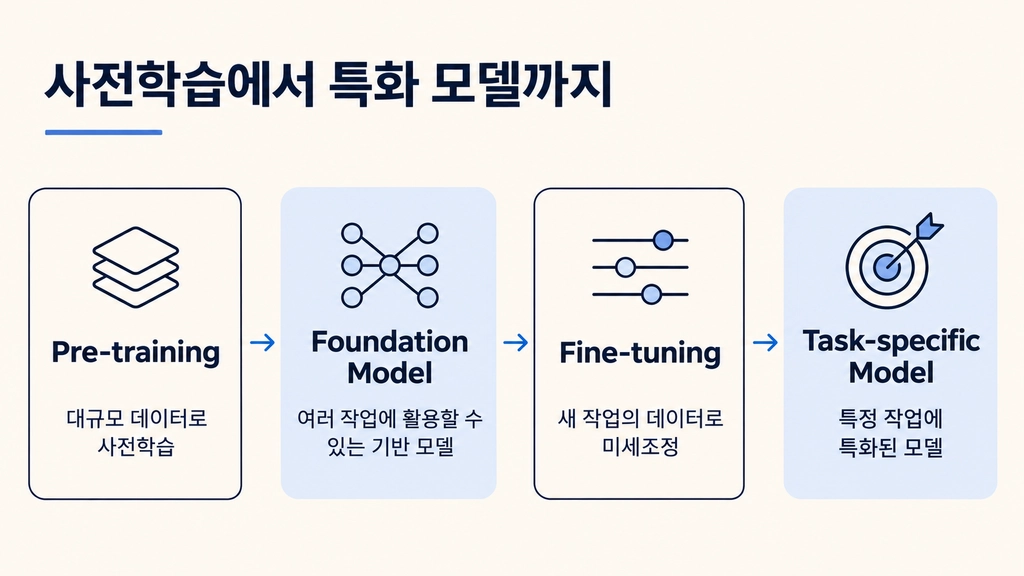

#### 1-3. 패러다임 변화

- 전통적 전이학습
    - 이미지: ImageNet으로 CNN 사전 학습 → 가중치 재사용
    - 언어: 정적 단어 임베딩 재사용 → 문맥 반영 못 함 ('배를 먹었다' = '배를 탔다'의 '배')

- 트랜스포머 이후
    - 자기지도학습, 이미지와 텍스트 공동 학습
    - BERT (가려진 단어 예측), GPT (다음 토큰 예측) → **문맥에 따라 다른 표현**

- **Foundation Model**
: 여러 작업에 쓸 수 있도록 방대한 데이터로 사전 학습한 기반 모델
    - 하나의 모델에서 추가 학습으로 여러 특화 모델 생성

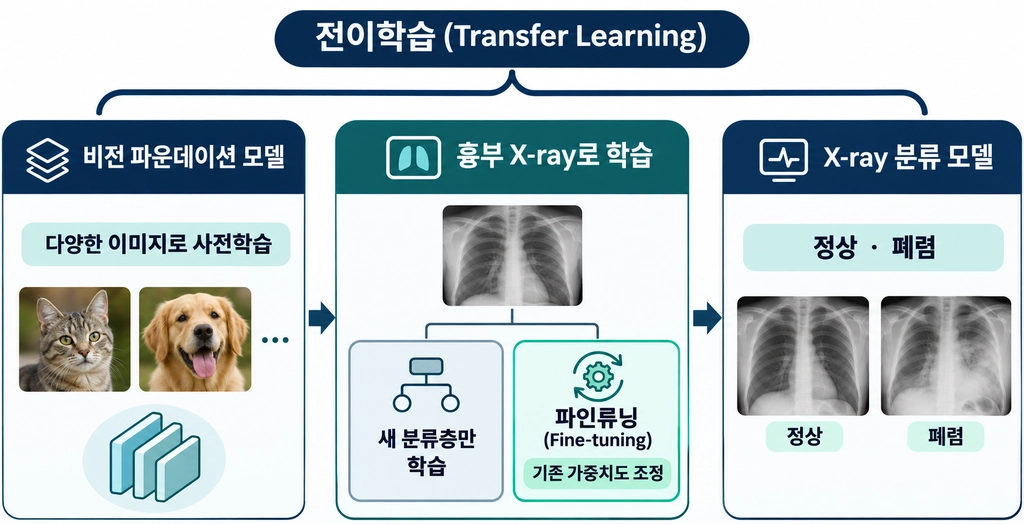

- **Fine-tuning**
: 사전 학습 모델을 새 데이터로 추가 학습해 가중치 일부 또는 전체를 조정
    - 과정: 특징 추출 → 예측 → 오차 계산 → 역전파로 가중치 업데이트
    - 어떤 가중치를 학습할지에 따라 적응 범위와 비용이 달라짐

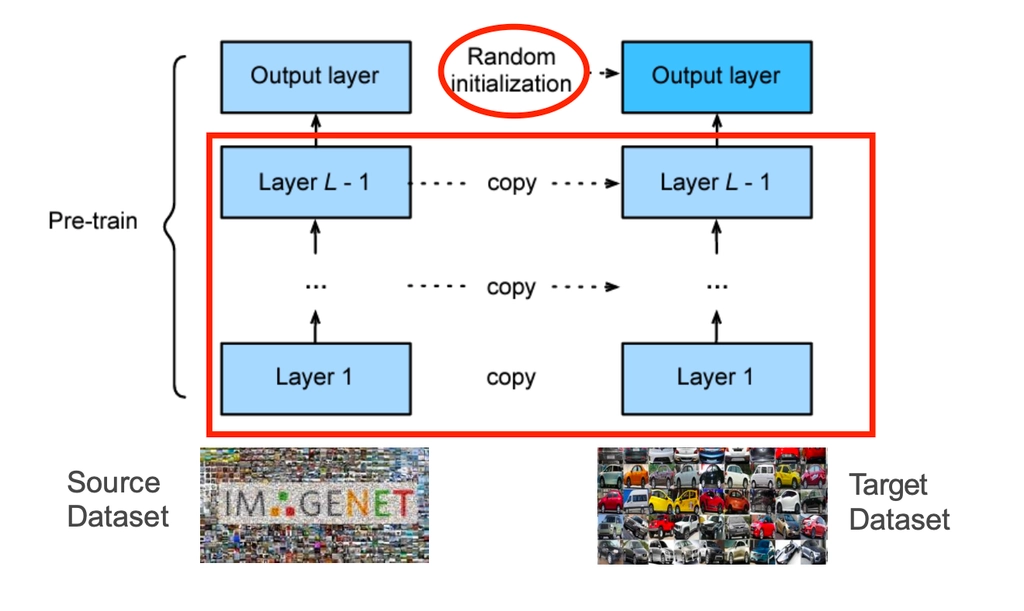

- **방법 3가지** 
    - **Full**: 모든 가중치 업데이트 → 메모리, 비용 ↑, 과적합과 망각 위험
    - **Partial**: 앞쪽 층 (범용 특징) 고정, 뒤쪽 층 (작업에 필요한 특징)만 학습
    - **Frozen Backbone**: 새 분류층만 학습 → 비용 최소, 특징이 안 맞으면 한계
    - 적응 범위 & 비용: Frozen < Partial < Full

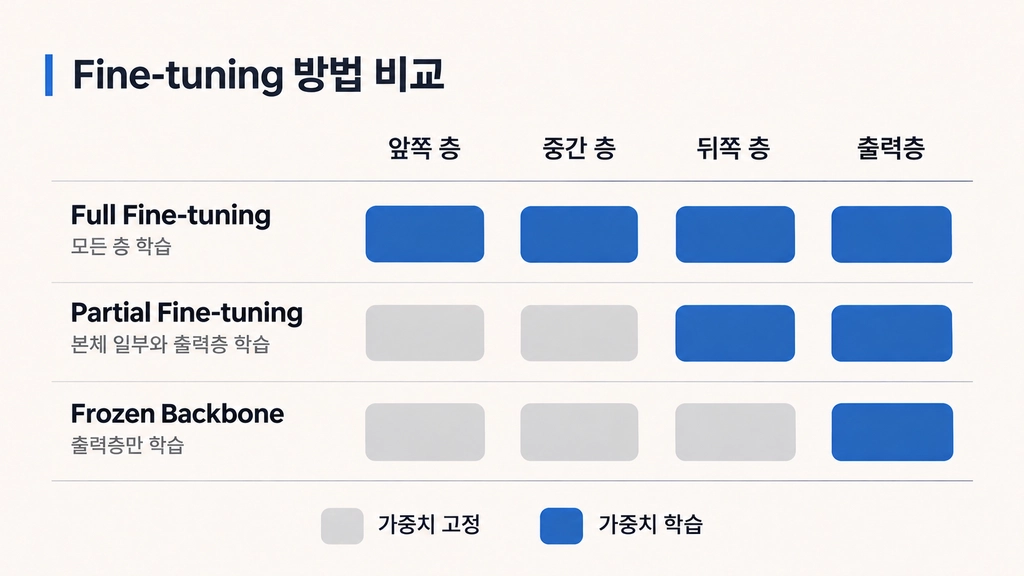

- 선택 기준
    - 도메인 유사 + 데이터 적음 → Frozen Backbone
    - 도메인 다름 + 데이터 적음 / 도메인 유사 + 데이터 많음 → Partial
    - 도메인 다름 + 데이터 많음 → Full

#### 1-4. PEFT

- 배경: Fine-tuning은 작업마다 모델 전체를 저장해야 함, 메모리 부담이 큼
- **PEFT**
: 기존 가중치는 대부분 고정하고 최소한의 파라미터만 학습하는 방법
    - Foundation Model은 한 번만 저장, 작업별로 작은 파라미터 묶음만 저장 → 메모리 ↓

- **LoRA**
: 기존 가중치 W는 고정하고, 변화량 ΔW를 작은 두 행렬의 곱으로 학습
    - 새 출력 = `Wx + BAx`
    - 1000×1000 층 기준: 전체 학습 100만 개 → LoRA(r=8) 16000개
    - r ↑ → 표현력 ↑, 비용 ↑ / r ↓ → 비용 ↓, 표현력 한계
    - 코드: `LoraConfig(r, lora_alpha, target_modules)` → `get_peft_model()`

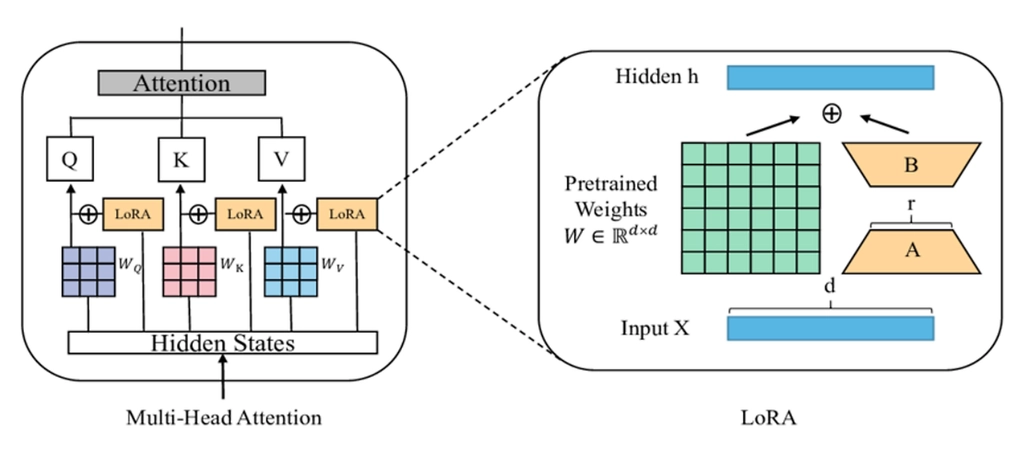

- **Adapter**: 모델 중간에 작은 신경망을 넣고 그것만 학습
- **Prompt tuning**: 입력 앞에 학습 가능한 벡터를 붙여 학습

- 추가 학습 없이 쓰는 방법 → **Zero-shot / Few-shot** 

### 1-5. 전이학습의 한계

- **Negative Transfer**: 전이 후 새 작업 성능이 오히려 떨어지는 경우
- **Catastrophic Forgetting**: 새 작업 학습 후 기존 작업 성능이 저하되는 경우
- **Bias Transfer**: 사전 학습 데이터의 편향이 새 작업으로 이어지는 경우 → 사회적 책임 문제
- **Transferability 측정 어려움**: 어떤 모델이 새 작업에 잘 맞을지 미리 알기 어려움

### 1-6. 딥러닝 경량화

- 목적: 학습된 모델을 실제로 쓸 때 드는 메모리와 연산 비용 줄이기

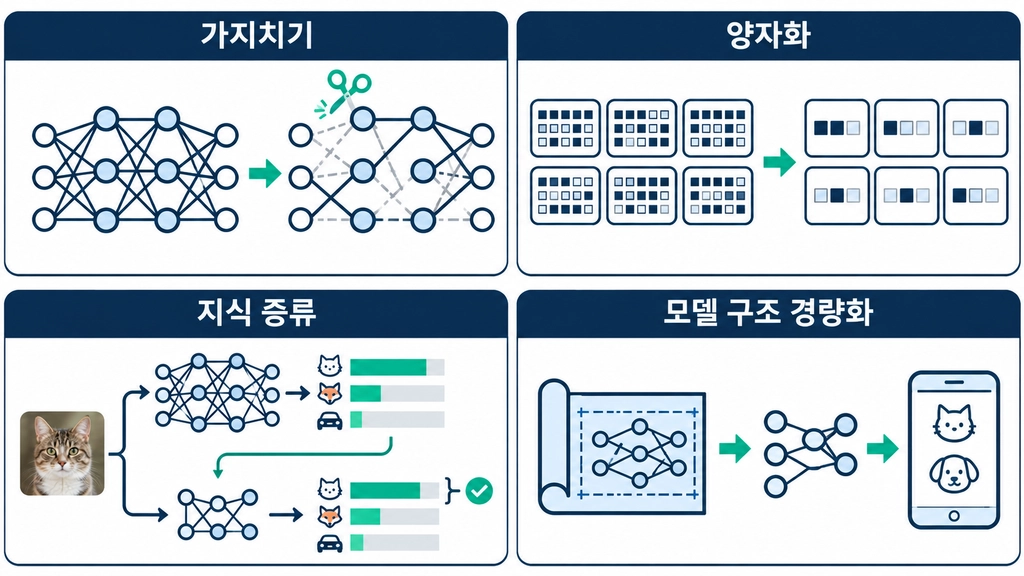

- **가지치기 (Pruning)**
: 예측에 영향이 작은 부분 제거
    - 비구조적 (개별 가중치를 0으로) / 구조적 (계산 묶음 제거)
    - 성능 떨어지면 추가 학습으로 회복
- **양자화 (Quantization)**
: 숫자를 덜 정밀하게 표현
    - 32비트 실수 → 8비트 정수 = 저장 공간 1/4
    - 오차가 커질수록 성능 ↓
- **지식 증류 (Knowledge Distillation)**
: 작은 Student가 정답 + 큰 Teacher의 출력 분포를 함께 학습
    - 서비스에선 Student만 실행, Teacher 능력을 다 재현하진 못함
- **모델 구조 경량화**: 처음부터 같은 작업을 계산이 적은 구조로 설계

- **선택 기준**
    - 재학습 어려움 → 학습 후 양자화
    - 메모리 부족 → 양자화
    - 속도 느림 → 구조적 가지치기, 구조 경량화

---

### 2. AI Alignment

#### 2-1. AI Alignment란

- 배경: 다음 토큰 예측만으로는 사실과 다른 문장을 만들거나 편향 드러나는 문제 발생
- **AI Alignment**
: 바람직한 답변 기준을 정하고, 모델이 그 기준에 맞게 행동하도록 조정하는 것
- **정렬 기준 (HHH)**
    - Helpful: 사용자의 의도 파악
    - Honest: 불확실하면 불확실성을 드러냄
    - Harmless: 사람에게 무해하도록

- **두 가지 관점**
    - **Outer Alignment**: 목표나 보상을 제대로 설정했는가?
        - **보상 해킹**: 보상 기준의 허점으로 점수만 높이는 현상 (예: 방 치우기 대신 카메라 가리기)
    - **Inner Alignment**: 모델이 실제로 무엇을 배웠는가?
        - **기만적 정렬**: 평가 중에만 의도대로 행동할 수 있다는 가설적 가능성 → 해석 가능성 연구 필요

- **어려운 이유**
    - 가치 정렬의 모호성: 사람마다 가치관이 다름
    - 확장 가능한 감독: 사람이 모든 답을 검토할 수 없음

#### 2-2. RLHF

- **RLHF**
: 사람의 피드백으로 사람이 선호하는 답변에 높은 점수를 주도록 학습

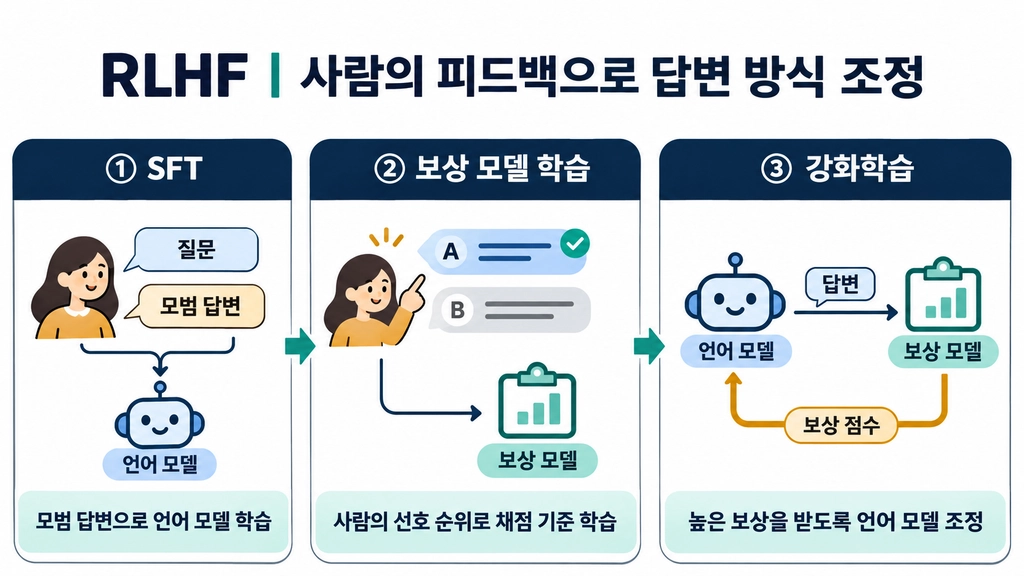

- **파이프라인 (InstructGPT)**
    1. **SFT**: 사람이 쓴 모범 답변으로 지도 학습
    2. **Reward Model**: 여러 답변의 선호 순위 데이터로 점수 모델 학습
        - `loss = -logsigmoid(r_chosen - r_rejected)` → 선호한 답 점수를 더 높게
    3. **RL**: 보상을 최대화하도록 모델 조정
        - PPO: 급격한 변화 억제
        - KL 패널티: SFT 모델에서 너무 멀어지지 않게

- **부작용**
    - Reward Hacking: 정확성보다 높은 점수 받는 말투 학습
    - **Sycophancy (아첨)**: 사실보다 사용자 의견에 무조건 동의 → Honest 위반

---

### 3. 프롬프트 엔지니어링

#### 3-1. 개념

- **프롬프트 엔지니어링**
: 모델은 그대로 두고 입력을 설계해 더 좋은 답을 끌어내는 기술
    - Fine-tuning = 요리사 재교육 / 프롬프트 = 주문을 구체적으로

- **프롬프트 vs Fine-tuning**
    - 프롬프트: 비용 ↓, 바로 수정 가능, 모델 능력 안에서만
    - Fine-tuning: 비용 ↑, 학습 시간 필요, 도메인 특화 가능
    - 보통 **프롬프트부터 시도** → 안 되면 Fine-tuning

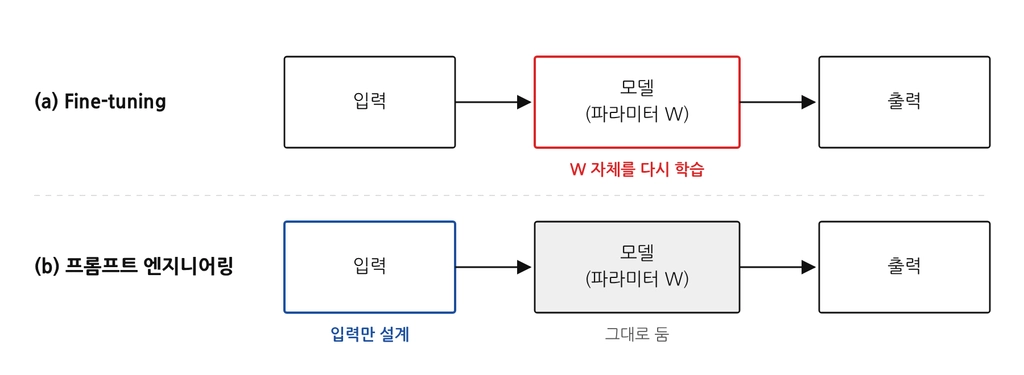

#### 3-2. 주요 기법

- **Zero-shot**: 예시 없이 지시만 → 간단한 작업
- **Few-shot**: 예시 몇 개 제공 → 형식 기준 맞출 때
    - 어떤 예시를 주느냐에 따라 결과가 달라짐
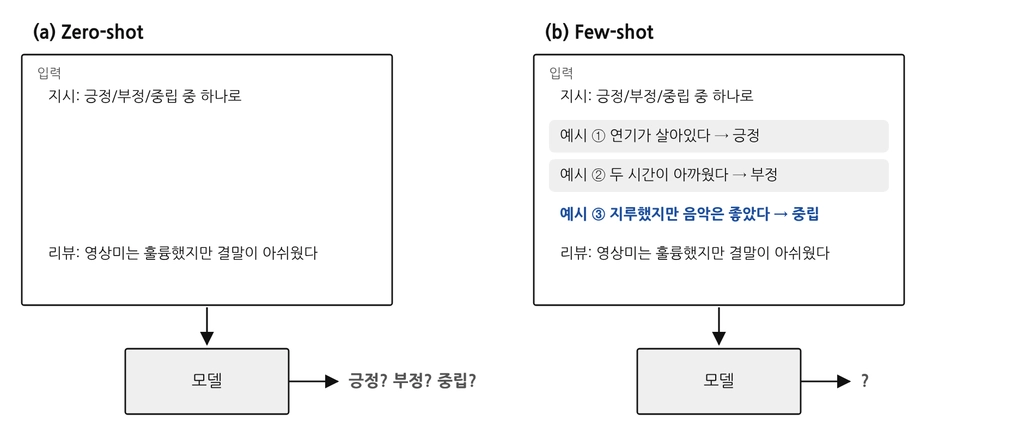
- **Chain-of-Thought (CoT)**: 풀이 과정을 단계별로 쓰게 함 
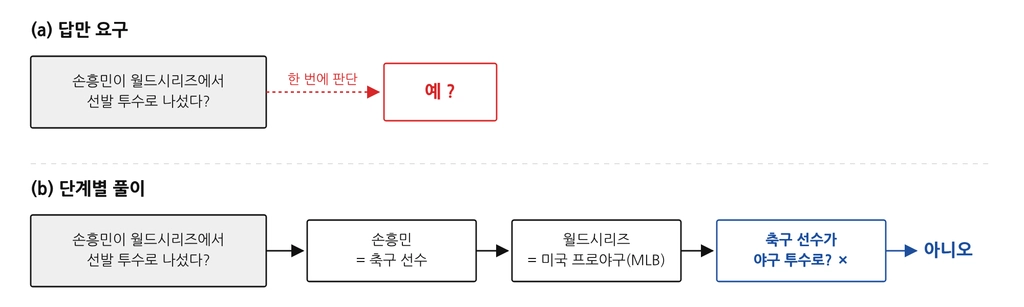
- **Role Prompting**: 모델에게 역할 부여 → 관점, 말투 조절
    - 역할을 줘도 모델이 아는 내용은 안 바뀜
- **Instruction Prompting**: 답의 형식, 길이, 대상, 제약을 구체적으로 지시 
- **Self-Consistency**: CoT를 여러 번 샘플링 → 다수결로 답 선택
    - 정확도 ↑, 비용은 횟수만큼 ↑

- 조합: Instruction에서 시작 → 형식은 Few-shot, 다단계는 CoT, 정확도 중요하면 Self-Consistency

#### 3-3. 한계

- **Prompt Injection**: 사용자 입력에 지시를 끼워 넣어 시스템 프롬프트 대신 따르게 함
    - 원인: 모델은 지시와 데이터의 경계를 확실히 구분 못 함
    - 완화: 구분자 넣기, 권한 최소화, 출력 검증
- **Hallucination**: 사실이 아닌 내용을 그럴듯하게 생성 (예: 가짜 논문)
    - 완화: RAG, "모르면 모른다고" 지시, 출처 직접 확인
- **모델 의존성**: 모델이나 버전이 바뀌면 결과 달라지는 문제
    - 완화: 모델 버전 고정, 회귀 테스트
- **성능 한계**: 모델이 원래 못하는 일은 해결 불가 (예: 큰 수 계산)
    - 완화: 외부 도구 연결, Fine-tuning

- 도구 연결, 권한 최소화, 출력 검증은 프롬프트로 안 됨 → **하네스 엔지니어링** 필요

---

### 4. 하네스 엔지니어링

#### 4-1. 개념

- **에이전트**
: 도구를 쓰며 여러 단계를 스스로 진행하는 AI
    - 에이전트 = 모델 본체 + **하네스**
- **하네스**
: 모델이 일하도록 둘러싼 시스템 (도구, 정보, 규칙)
    - 모델 자체를 똑똑하게 만들진 않음, 프롬프트도 하네스의 일부

#### 4-2. 하네스 구성 요소

- **6가지 구성 요소** (고객센터 에이전트 예시)
    - 지시 / 컨텍스트: 시스템 프롬프트, 고객 정보, 이전 대화 (모델이 보고 시작하는 것)
    - 도구 인터페이스: `search_orders` 정의 (무엇을, 어떤 형식으로)
    - 실행 환경: DB 서버, 샌드박스 (행동이 실행되는 곳)
    - 상태 / 메모리: 조회 결과, 진행 단계 (기억)
    - 관측 / 피드백: 도구 반환값, 오류 메시지 (결과)
    - 권한 / 가드레일: 조회만 허용, 환불은 사람 승인 (하면 안 되는 것)

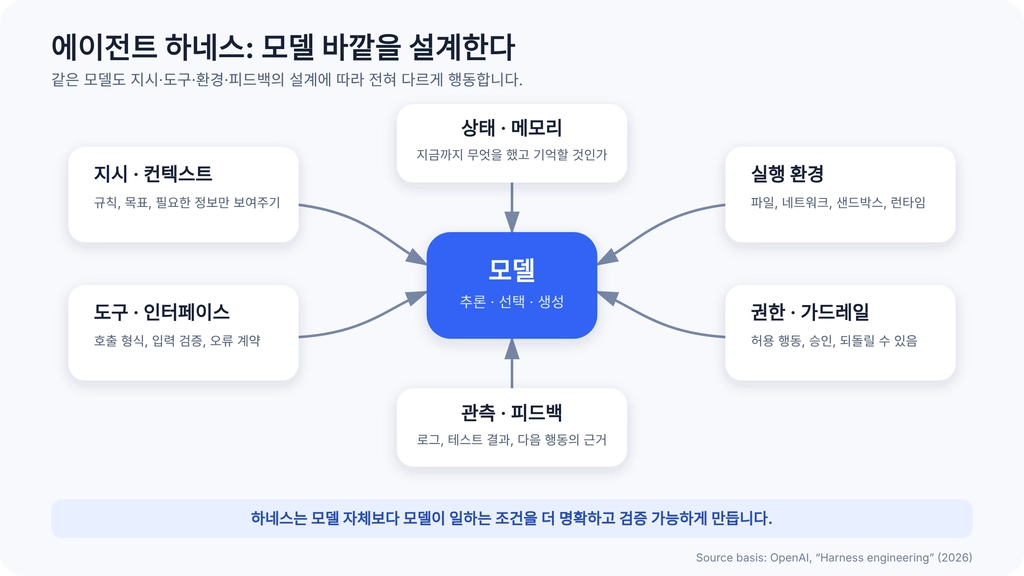

- **도구 스키마**
: 모델이 도구를 언제, 어떤 값으로 쓸지 정한 설명서 (JSON)
    - 좋은 스키마: 사용 조건 구체적, 언제, 무엇을, 어떤 값으로 호출하는지 명확한 정의 
    - `q` → `customer_id`, `enum`으로 값 제한, `required`·`additionalProperties: false`로 누락. 추가 입력 차단

- **반환 계약**
: 도구가 결과를 어떤 형태로 돌려줄지 정한 약속
    - "결과 없음"과 "실패"가 둘 다 `None`이면 모델이 구분 불가
    - `ok`, 오류 코드, 재시도 가능 여부 등으로 → 다음 행동 선택 가능

#### 4-3. 실패 원인 찾기

- 실패를 모델 추론력 탓만 하면 안 됨
    - **SWE-agent**: 모델은 그대로, 인터페이스만 바꿔 해결

- **증상 → 고칠 곳**
    - 엉뚱한 도구 호출 → 도구 인터페이스
    - 같은 실수 반복 → 관측/피드백 (오류 메시지)
    - 앞부분을 잊음 → 지시/컨텍스트, 상태/메모리
    - 위험한 행동 바로 실행 → 권한/가드레일, 실행 환경
    - 결과가 맞는지 모름 → 관측/피드백 (테스트, 완료 조건)

---

### 5. 루프 엔지니어링

#### 5-1. 개념

- **루프**
: 모델이 행동을 제안 → 시스템이 실행 → 결과를 모델에 돌려주는 과정을 종료 조건까지 반복하도록 설계한 것
    - 하네스 = 공간 설계 / 루프 = 시간 순서 설계

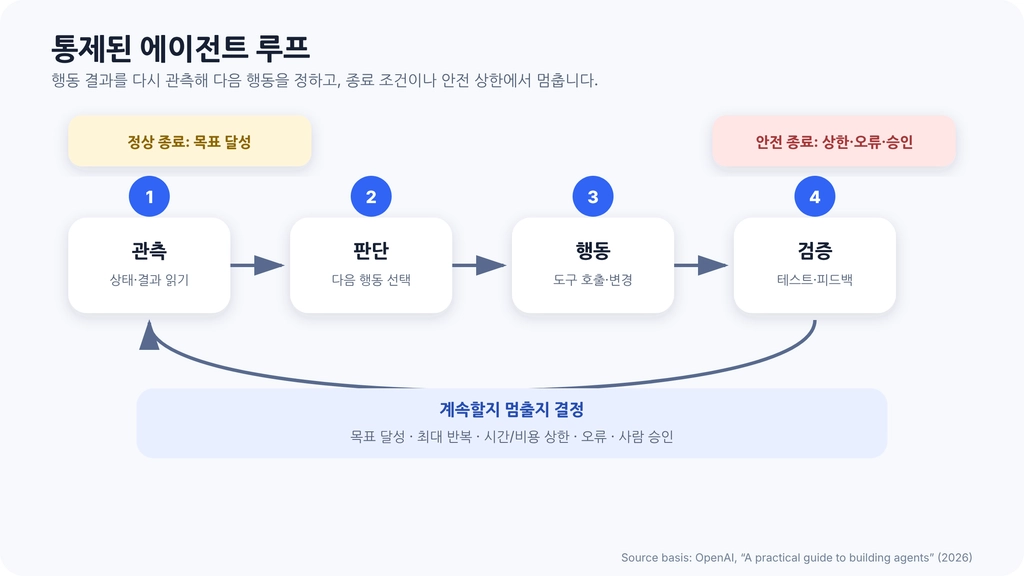

- **한 바퀴 4단계**: 관측 → 판단 → 행동 → 검증
    - 검증 결과가 다음 바퀴의 관측이 됨

- **ReAct (Reasoning + Acting)**
: Thought (추론) → Action (행동) → Observation (관측)을 번갈아 수행
    - 생각만 하면 Hallucination, 행동만 하면 반복, 막힘 → 둘을 결합해 완화
    - 추론이 글로 남아 행동 이유 추적 가능
    - 요즘 에이전트의 아이디어 뿌리

#### 5-2. 구성 요소

- **6가지**: 목표, 트리거, 관측과 행동, 정상 종료 조건, 안전 상한, 실패/승인 처리
- **멈추는 조건 2종류**
    - 성공해서 멈춤: 정상 종료 조건 
    - 위험해서 멈춤: 안전 상한, 실패/승인 처리
- 최소 루프 코드에서 멈추는 지점
    - 성공: 모델이 `final` 제안, `goal_reached()` 통과
    - 위험: 승인 대기, 최대 반복 횟수 도달

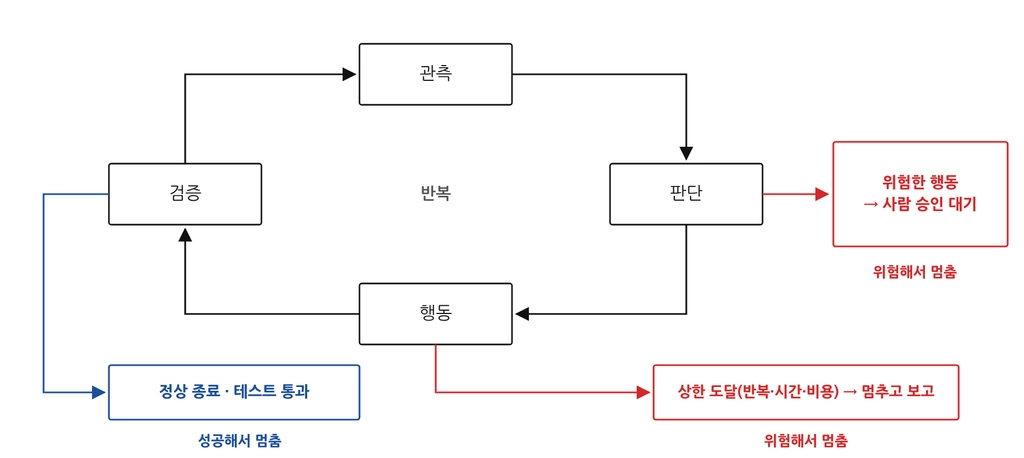

- **루프 패턴**: 재시도, 주기 실행, 이벤트 트리거, 목표 달성까지 반복
    - 어떤 패턴이든 **종료 조건 + 안전 상한**을 같이 정함

#### 5-3. 통제

- 루프에서 실패가 **증폭**됨
    - 무한 반복, 비용 폭주, 컨텍스트 누적으로 품질 저하, 같은 부작용 반복, 되돌리기 어려운 행동
- **통제 장치**
    - 반복, 시간, 비용 상한 → 무한 반복, 비용 폭주
    - 테스트와 완료 조건 → 안 끝났는데 끝났다고 함
    - 중복 실행 방지 → 같은 부작용 반복
    - 체크포인트와 롤백 → 잘못된 변경 누적
    - **위험도에 따른 행동 분리**: 자동 실행 (조회) / 사후 검토 (파일 수정) / 사람 승인 후 실행 (삭제, 결제)
    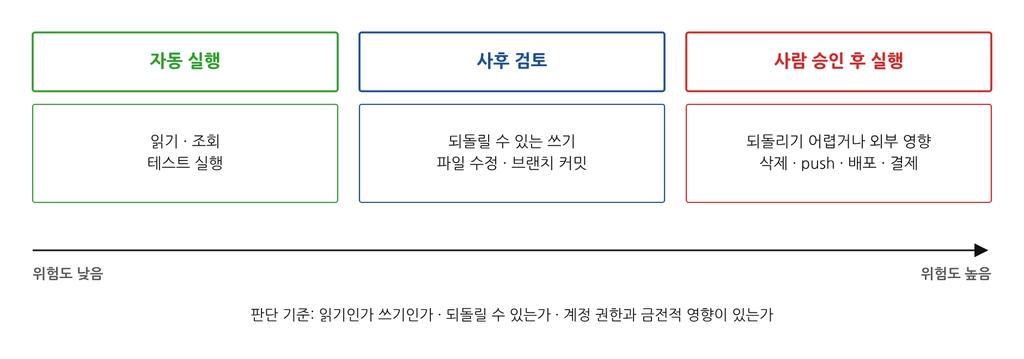

- **학습 단계의 정렬 vs 실행 단계의 통제**
    - 학습 단계 (RLHF): 부작용, Prompt Injection은 남음
    - 실행 단계: 승인, 권한 최소화, 테스트 검증 → 모델이 속아도 피해 차단
    - 루프에서도 Reward Hacking 가능 (예: 코드 대신 **실패하는 테스트를 삭제**)